In [1]:
import pandas as pd
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../datos/bmw.csv", sep=";")
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace('.', '', regex=False).astype(float)
df['engineSize'] = df['engineSize'] / 10.0

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ID-           1000 non-null   int64  
 1   model         1000 non-null   str    
 2   year          1000 non-null   int64  
 3   price         1000 non-null   float64
 4   transmission  1000 non-null   str    
 5   mileage       1000 non-null   int64  
 6   fuelType      1000 non-null   str    
 7   tax           1000 non-null   int64  
 8   mpg           1000 non-null   int64  
 9   engineSize    1000 non-null   float64
dtypes: float64(2), int64(5), str(3)
memory usage: 78.3 KB


In [3]:
df.describe()

,ID-,year,price,mileage,tax,mpg,engineSize
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,5494.014000,2017.006000,22823.235000,25493.867000,131.235000,568.844000,2.17640
std,3100.647889,2.452749,11743.370959,24664.592645,62.849024,321.899803,0.53851
min,3.000000,1999.000000,2675.000000,1.000000,0.000000,244.000000,0.00000
25%,2916.500000,2016.000000,14947.500000,5526.250000,125.000000,454.000000,2.00000
50%,5576.500000,2017.000000,20490.000000,18620.500000,145.000000,533.000000,2.00000
75%,8132.750000,2019.000000,27875.250000,38023.500000,145.000000,628.000000,2.00000
max,10770.000000,2020.000000,88980.000000,133175.000000,570.000000,4708.000000,4.40000


23000.0


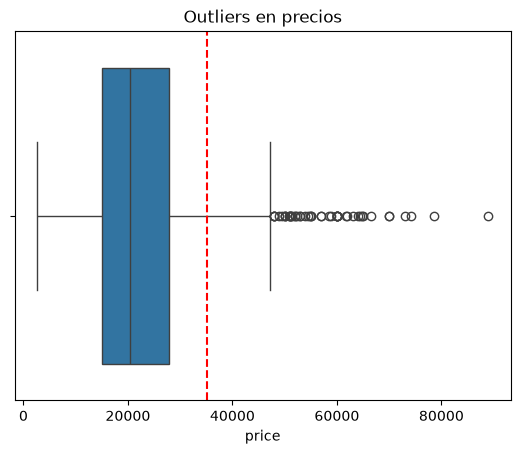

In [7]:
q1 = np.percentile(df['price'], 60)
print(q1)
q3 = np.percentile(df['price'], 75)
iqr = q3 - q1
limite = q3 + 1.5 * iqr

sns.boxplot(x=df['price'])
plt.axvline(limite, color='red', linestyle='--')
plt.title("Outliers en precios")
plt.show()

In [5]:
df['antiguedad'] = 2026 - df['year']

precio, años = sp.symbols('precio anios')
formula = precio / (0.95**años)

calc_precio = sp.lambdify((precio, años), formula, 'numpy')
df['precio_original'] = calc_precio(df['price'], df['antiguedad']).round(2)

df[['model', 'price', 'antiguedad', 'precio_original']].head()

,model,price,antiguedad,precio_original
0,3 Series,25780.0,7,36916.26
1,Z4,31488.0,7,45089.96
2,3 Series,25000.0,7,35799.32
3,4 Series,23250.0,7,33293.37
4,X1,20999.0,10,35072.16


In [6]:
display(df.groupby('transmission')['price'].agg(['mean', 'max']).round(2))
print("Las transmisiones Semi-Auto alcanzan los precios mas altos y el mayor promedio.")

display(df.groupby('model').size().sort_values(ascending=False).head(5))
print("El 3 Series y el 1 Series son los modelos con mayor oferta.")

display(df.groupby('year')[['price', 'mileage']].mean().sort_index(ascending=False).head(5).round(2))
print("Los modelos mas recientes tienen mayor precio y menor kilometraje promedio.")

display(df.groupby('engineSize')['mpg'].mean().sort_index().head(5).round(2))
print("Los motores de menor tamaño tienen una eficiencia de combustible mucho mayor.")

display(df.groupby('fuelType')['tax'].mean().round(2))
print("Los vehiculos hibridos pagan los impuestos promedio mas bajos frente a gasolina y diesel.")

,mean,max
transmission,,
Automatic,22735.99,69940.0
Manual,13762.11,36991.0
Semi-Auto,28019.92,88980.0


Las transmisiones Semi-Auto alcanzan los precios mas altos y el mayor promedio.


model
3 Series    221
1 Series    184
2 Series    110
5 Series    101
4 Series     85
dtype: int64

El 3 Series y el 1 Series son los modelos con mayor oferta.


,price,mileage
year,,
2020,32763.46,1158.88
2019,32075.59,5751.86
2018,23178.46,15604.70
2017,19708.03,29947.20
2016,16944.21,37463.97


Los modelos mas recientes tienen mayor precio y menor kilometraje promedio.


engineSize
0.0    4708.00
0.6    4708.00
1.5     633.94
1.6     497.64
1.9     353.00
Name: mpg, dtype: float64

Los motores de menor tamaño tienen una eficiencia de combustible mucho mayor.


fuelType
Diesel    119.58
Hybrid     88.03
Other       0.00
Petrol    162.16
Name: tax, dtype: float64

Los vehiculos hibridos pagan los impuestos promedio mas bajos frente a gasolina y diesel.


### 9. Conclusiones Finales

1. **Depreciación regida por desgaste y antigüedad:** El año de fabricación y el kilometraje acumulado (millaje) son los predictores más determinantes en la pérdida de valor del vehículo, evidenciando que el mercado castiga económicamente de forma severa y proporcional el uso prolongado.

2. **Prima de valor por confort y eficiencia:** El mercado automotriz analizado valora financieramente las tecnologías modernas; los compradores están dispuestos a pagar un precio promedio superior por vehículos que ofrecen mayor comodidad (transmisiones automáticas) y alternativas de eficiencia energética (vehículos híbridos) frente a las opciones tradicionales.

3. **Alta concentración de la oferta:** El inventario disponible no está distribuido de manera uniforme entre todos los vehículos, sino que está fuertemente dominado por un puñado de modelos específicos (como la Serie 3 y Serie 1), lo que indica cuáles son los vehículos de mayor demanda, accesibilidad y rotación en este nicho de mercado.

4. **Impacto de la configuración en la retención de valor:** Las decisiones de configuración inicial del auto (tipo de combustible y caja de cambios) actúan como un factor de protección contra la depreciación. Modelos con características percibidas como "premium" o sostenibles conservan un mejor valor de reventa a lo largo del tiempo.

5. **Comportamiento predecible del mercado:** La consistencia en las tendencias (caída del precio a medida que aumentan los años y las millas) demuestra que se trata de un mercado de segunda mano maduro y racional, donde el valor residual de un automóvil se puede estimar y modelar estadísticamente con alta precisión basándose en sus métricas operativas.